# RQ3 check: Do claims form groups with similar flood risk?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

Notebook `04_research_questions.ipynb` answered RQ3 with seven building profiles, and said ground-level slab homes are about four times more likely to be high severity than elevated homes. This notebook checks that answer. It does not replace the class comparison of K-means, hierarchical clustering, and PCA. It uses the same cleaned file and the same 20,000-claim sample.

The check has two parts:

1. Refit the same 7-means clustering and read what the groups actually are.
2. Compare severity by foundation **inside Florida and outside Florida**, then set that next to published NFIP claims studies.

## 1. Setup

Same inputs as notebook 04: `outputs/nfip_claims_simple_clean.parquet` and `outputs/simple_feature_lists.json`. Run this notebook from the `notebooks` folder.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEED = 42
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)

work = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet')
with open('outputs/simple_feature_lists.json') as f:
    FL = json.load(f)

labeled = work['high_severity'].notna()
threshold = work.loc[work['high_severity'] == 1, 'buildingDamageAmount'].min()
print(f"Claims: {len(work):,}")
print(f"high_severity = 1 when building damage is at least ${threshold:,.0f}")
print(f"Share of claims with that label: {work.loc[labeled, 'high_severity'].mean():.1%}")
print('RQ3 features:', FL['RQ3'])

Claims: 276,570
high_severity = 1 when building damage is at least $106,127
Share of claims with that label: 20.0%
RQ3 features: ['flood_zone_family', 'foundationType', 'building_age', 'numberOfFloorsInTheInsuredBuilding', 'occupancyType', 'crsClassCode', 'totalBuildingInsuranceCoverage']


## 2. The same seven clusters

Notebook 04 dropped foundation code 0 (legacy policies with no recorded foundation), translated legacy occupancy codes into the Risk Rating 2.0 codes, and clustered a random sample of 20,000 claims. Payment and damage were not used to form the groups. The settings below are the same ones: one-hot encoding, log coverage, standard scaling, K-means with `k = 7`, `n_init = 10`, seed 42.

In [2]:
OLD_TO_NEW = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}
FOUNDATION = {
    '1': 'slab',
    '2': 'basement',
    '3': 'crawlspace',
    '4': 'piles',
    '5': 'piers',
    '6': 'walls',
}

w3 = work[work['foundationType'] != '0'].copy()
w3['occupancyType'] = w3['occupancyType'].replace(OLD_TO_NEW)
s3 = w3.sample(20000, random_state=SEED).copy()

NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]
X3 = pd.get_dummies(s3[FL['RQ3']], columns=NOM3, dtype=int)
X3['totalBuildingInsuranceCoverage'] = np.log1p(X3['totalBuildingInsuranceCoverage'])
X3s = StandardScaler().fit_transform(X3)

kmeans = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit(X3s)
s3['cluster'] = kmeans.labels_
print(f"Sample: {len(s3):,} claims, {X3.shape[1]} encoded columns")
print(s3['cluster'].value_counts().sort_index().rename('claims'))

Sample: 20,000 claims, 31 encoded columns
cluster
0    1307
1    3547
2    1557
3    1427
4    9723
5     491
6    1948
Name: claims, dtype: int64


In [3]:
profile = s3.groupby('cluster').agg(
    claims=('cluster', 'size'),
    median_building_age=('building_age', 'median'),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
    high_severity_share=('high_severity', 'mean'),
    median_payment_if_paid=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()),
)
profile['top flood zone'] = s3.groupby('cluster')['flood_zone_family'].agg(lambda x: x.value_counts().index[0])
profile['foundation'] = s3.groupby('cluster')['foundationType'].agg(
    lambda x: FOUNDATION[x.value_counts().index[0]]
)
profile.round(3)

,claims,median_building_age,median_coverage,florida_share,high_severity_share,median_payment_if_paid,top flood zone,foundation
cluster,,,,,,,,
0,1307,33.826,250000.0,0.539,0.053,11140.06,AE,walls
1,3547,44.271,250000.0,0.629,0.279,57754.62,AE,slab
2,1557,58.218,250000.0,0.321,0.150,22993.91,AE,crawlspace
3,1427,33.736,250000.0,0.607,0.073,10458.50,AE,piers
4,9723,50.735,250000.0,0.723,0.287,76066.26,AE,slab
5,491,41.851,70000.0,0.723,0.035,18118.62,AE,piles
6,1948,67.173,250000.0,0.041,0.064,14525.73,AE,basement


**What these groups are.** The cluster sizes match notebook 04 (9,723 in the largest group, 491 in the smallest), so this is the same fit. Each group has one dominant foundation, and every group's modal flood zone is AE. Median coverage is the $250,000 building cap in six groups. The remaining group (cluster 5, 491 claims) has median coverage of $70,000; notebook 04 identified it as mobile homes (occupancy code 14), and its modal foundation code is piles. The two slab groups have high-severity shares of 28% and 29%. The walls, piers, and basement groups are at 5%, 7%, and 6%. They do that because they are foundation codes, with Florida mixed in.

Notebook 04 also reported the separation scores. They are weak:

- Silhouette is **0.251** at k = 7 and **0.462** at k = 2. A score near 0.25 means the groups overlap.
- Hierarchical clustering agrees only partly with K-means (**ARI 0.367**). K-means on the 18 PCA components agrees less (**ARI 0.291**).
- PCA needs **18 of 31** components to reach 80% of the variance. PC1 explains 8.7% and PC2 explains 7.2%, and both mostly reload floors, occupancy, and foundation.

So "seven risk profiles" is a naming of the foundation codes. The methods do not recover one shared set of groups.

## 3. Other numbers of groups, DBSCAN, and the 20,000-row sample

Three questions about the fit in notebook 04:

- Could a different number of groups be the right one?
- What does DBSCAN find, and would KNN find groups?
- Why cluster 20,000 claims instead of all of them?

K-means needs k chosen in advance. Notebook 04 tried k = 2 through 8 and kept the best silhouette between 3 and 8, which was k = 7. The sweep below repeats that and goes on to k = 12. KNN (k-nearest neighbors) is a classifier: it needs labels already, then copies the label of nearby claims. It does not discover groups. The neighbor calculation that belongs here is the one DBSCAN uses to set its neighborhood radius.


 k  silhouette  smallest group  largest group
 2       0.462             491          19509
 3       0.248             491          16501
 4       0.196             491          12180
 5       0.187             491           9715
 6       0.218             491          10973
 7       0.251             491           9723
 8       0.206               6          10290
 9       0.221               6          10039
10       0.286              74           9995
11       0.287               6          10817
12       0.256               4           9044


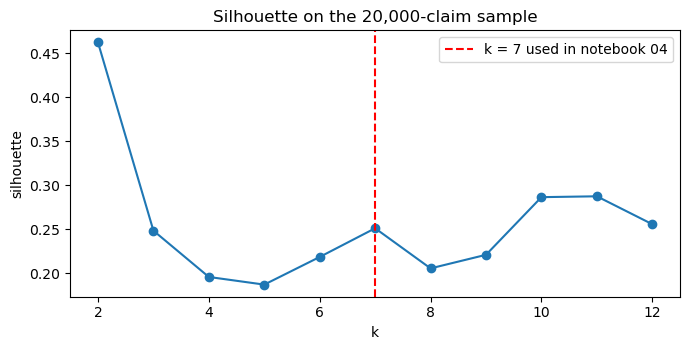

In [4]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

ks = range(2, 13)
sil_rows = []
for k in ks:
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3s).labels_
    sil_rows.append({
        'k': k,
        'silhouette': silhouette_score(X3s, labels, sample_size=5000, random_state=SEED),
        'smallest group': int(pd.Series(labels).value_counts().min()),
        'largest group': int(pd.Series(labels).value_counts().max()),
    })
sil_table = pd.DataFrame(sil_rows)
print(sil_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(sil_table['k'], sil_table['silhouette'], 'o-')
ax.axvline(7, color='red', ls='--', label='k = 7 used in notebook 04')
ax.set_xlabel('k')
ax.set_ylabel('silhouette')
ax.set_title('Silhouette on the 20,000-claim sample')
ax.legend()
plt.tight_layout()
plt.show()


In [5]:
labels2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X3s).labels_
s3['k2'] = labels2
k2_profile = s3.groupby('k2').agg(
    claims=('k2', 'size'),
    high_severity_share=('high_severity', 'mean'),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
)
k2_profile['top occupancy'] = s3.groupby('k2')['occupancyType'].agg(lambda x: x.value_counts().index[0])
k2_profile['top floors'] = s3.groupby('k2')['numberOfFloorsInTheInsuredBuilding'].agg(lambda x: x.value_counts().index[0])
k2_profile['top foundation'] = s3.groupby('k2')['foundationType'].agg(lambda x: FOUNDATION.get(x.value_counts().index[0], x.value_counts().index[0]))
k2_profile.round(3)


,claims,high_severity_share,median_coverage,florida_share,top occupancy,top floors,top foundation
k2,,,,,,,
0,19509,0.219,250000.0,0.585,11.0,1.0,slab
1,491,0.035,70000.0,0.723,14.0,5.0,piles


**What the sweep shows.** The highest silhouette is k = 2 (0.46). That split is not two risk profiles. One group has 491 claims: occupancy 14 (mobile homes), floors code 5, median coverage $70,000. The other group has the other 19,509 claims. From k = 3 through k = 7 the smallest group stays at 491, so those fits are the mobile-home group plus further splits of the large group. k = 7 is only a hair above k = 3 (0.251 versus 0.248). Past k = 8 the score rises a little because groups of size 4 to 6 appear. None of these scores says the claims form distinct, well-separated profiles. A silhouette near 0.25 means the groups overlap. The k = 2 score is higher because one tiny group sits far from a single crowd, not because the crowd itself splits cleanly.


In [6]:
min_samples = 16  # same neighborhood size as lecture 10
nn = NearestNeighbors(n_neighbors=min_samples).fit(X3s)
kdist = np.sort(nn.kneighbors(X3s)[0][:, -1])
print('Distance to the 16th neighbor: median '
      f'{np.median(kdist):.2f}, 90th percentile {np.percentile(kdist, 90):.2f}')

# eps = 2 sits near that 90th percentile. A smaller eps only makes more tiny groups.
db_labels = DBSCAN(eps=2.0, min_samples=min_samples, n_jobs=-1).fit(X3s).labels_
s3['db'] = db_labels
n_noise = int((db_labels == -1).sum())
n_clusters = len(set(db_labels)) - (1 if n_noise else 0)
sizes = pd.Series(db_labels)
sizes = sizes[sizes >= 0].value_counts()
kept = db_labels >= 0
db_sil = silhouette_score(X3s[kept], db_labels[kept], sample_size=5000, random_state=SEED)
print(f'DBSCAN clusters: {n_clusters}    noise claims: {n_noise:,} ({n_noise / len(db_labels):.1%})')
print(f'Clusters with at least 200 claims: {(sizes >= 200).sum()}    smaller than 50: {(sizes < 50).sum()}')
print(f'Silhouette on the non-noise claims: {db_sil:.3f}')

big = s3[s3['db'].isin(sizes[sizes >= 400].index)]
db_profile = big.groupby('db').agg(
    claims=('db', 'size'),
    high_severity_share=('high_severity', 'mean'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
)
db_profile['foundation'] = big.groupby('db')['foundationType'].agg(
    lambda x: FOUNDATION[x.value_counts().index[0]])
db_profile['foundation share'] = big.groupby('db')['foundationType'].agg(
    lambda x: x.value_counts(normalize=True).iloc[0])
db_profile['top occupancy'] = big.groupby('db')['occupancyType'].agg(lambda x: x.value_counts().index[0])
db_profile.sort_values('claims', ascending=False).round(3)


Distance to the 16th neighbor: median 0.29, 90th percentile 2.06


DBSCAN clusters: 110    noise claims: 1,562 (7.8%)
Clusters with at least 200 claims: 20    smaller than 50: 60
Silhouette on the non-noise claims: 0.591


,claims,high_severity_share,florida_share,median_coverage,foundation,foundation share,top occupancy
db,,,,,,,
0,5555,0.356,0.862,250000.0,slab,1.0,11.0
17,1277,0.100,0.356,250000.0,slab,1.0,11.0
1,1167,0.255,0.715,250000.0,slab,1.0,11.0
16,676,0.173,0.396,248500.0,crawlspace,1.0,11.0
2,510,0.283,0.563,364000.0,slab,1.0,18.0
24,493,0.041,0.574,250000.0,piers,1.0,11.0
7,432,0.044,0.037,250000.0,basement,1.0,11.0
5,419,0.023,0.632,250000.0,walls,1.0,11.0


**What DBSCAN shows.** With a neighborhood of 16 claims and radius 2 (about the 90th percentile of the distance to the 16th neighbor), DBSCAN returns about 110 clusters and marks about 8% of claims as noise. Sixty of those clusters have fewer than 50 claims. The clusters large enough to describe are pure: each one is a single foundation code, and usually a single occupancy code. The largest is slab, single-family, mostly Florida, with a high-severity share around 36%. A basement group outside Florida is around 4%. That is the same foundation pattern as k-means, cut into more pieces.

The silhouette on the non-noise claims is about 0.59. That number looks strong only because each cluster is a pure category and the points that do not fit are dropped before the score. It is not evidence of a few distinct risk profiles.

KNN would not change this. A k-nearest-neighbors classifier predicts a label that already exists. RQ3 has no label to predict. The 16-neighbor distance above is the part of that idea that clustering can use, and it is the input to DBSCAN.


In [7]:
# The 20,000-row sample was for speed. Fit the same k-means on every claim with a foundation.
NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]
X_full = pd.get_dummies(w3[FL['RQ3']], columns=NOM3, dtype=int)
X_full['totalBuildingInsuranceCoverage'] = np.log1p(X_full['totalBuildingInsuranceCoverage'])
X_full_s = StandardScaler().fit_transform(X_full)
draw = np.random.default_rng(SEED).choice(len(X_full_s), 5000, replace=False)

full_rows = []
for k in (2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_full_s).labels_
    counts = pd.Series(labels).value_counts()
    full_rows.append({
        'k': k,
        'claims': len(labels),
        'silhouette on 5,000': silhouette_score(X_full_s[draw], labels[draw]),
        'largest share': counts.max() / len(labels),
        'smallest group': int(counts.min()),
    })
print(f'Claims with a recorded foundation: {len(w3):,}')
print(pd.DataFrame(full_rows).round(3).to_string(index=False))

second = w3.sample(20000, random_state=7)
X2 = pd.get_dummies(second[FL['RQ3']], columns=NOM3, dtype=int)
X2['totalBuildingInsuranceCoverage'] = np.log1p(X2['totalBuildingInsuranceCoverage'])
X2s = StandardScaler().fit_transform(X2)
print()
print('Second 20,000-claim sample (seed 7)')
for k in (2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2s).labels_
    print(f"  k = {k}  silhouette {silhouette_score(X2s, labels, sample_size=5000, random_state=SEED):.3f}")


Claims with a recorded foundation: 250,406
 k  claims  silhouette on 5,000  largest share  smallest group
 2  250406                0.513          0.975            6385
 7  250406                0.229          0.575            3971

Second 20,000-claim sample (seed 7)


  k = 2  silhouette 0.454


  k = 7  silhouette 0.201


**Why 20,000 rows.** A silhouette score compares claims with each other, and that cost grows with the square of the number of rows. Notebook 04 drew 20,000 claims so the k sweep and the hierarchical tree would finish. The sample is not what makes the groups weak.

On all 250,406 claims with a recorded foundation, k = 2 still puts about 97.5% of claims in one group (silhouette about 0.51 on a 5,000-claim draw). The small group is mobile homes again. k = 7 has silhouette about 0.23, and the largest group holds about 58% of claims. A second 20,000-claim draw (seed 7) gave silhouette 0.45 at k = 2 and 0.20 at k = 7, so k = 7 is not a stable score either. Using every row does not uncover a sharper set of profiles.


## 3.1 Does PCA find the groups?

PCA does not create clusters. It builds new columns that keep as much of the spread as possible, and then we can cluster those columns. Notebook 04 kept 18 components to reach 80% of the variance and found that k-means there only partly agreed with k-means on the original columns (ARI 0.29). The check below asks a sharper question: if the groups look separated in the PCA plane, are they still separated when scored on the original columns?


PC1 8.7%, PC2 7.2%, together 15.9%
Components for 80% of variance: 18 of 31 (80.3%)


        space  k  silhouette in the PCA space  silhouette on the original columns  agreement with k = 7 on the original columns
 2 components  2                        0.473                               0.188                                         0.418
 2 components  7                        0.493                               0.127                                         0.379
18 components  2                        0.502                               0.462                                         0.041
18 components  7                        0.268                               0.217                                         0.291


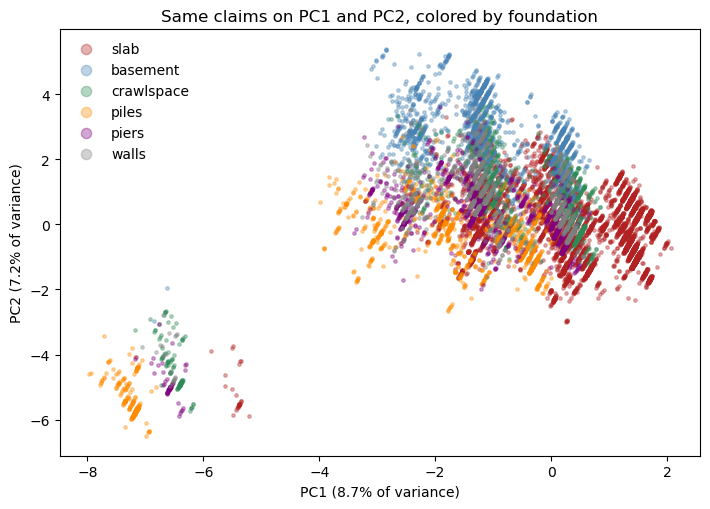

In [8]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

pca = PCA(random_state=SEED).fit(X3s)
ev = pca.explained_variance_ratio_
cum = np.cumsum(ev)
n80 = int(np.argmax(cum >= 0.80) + 1)
Z = pca.transform(X3s)
print(f'PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, together {ev[0] + ev[1]:.1%}')
print(f'Components for 80% of variance: {n80} of {X3s.shape[1]} ({cum[n80 - 1]:.1%})')

labels7 = s3['cluster'].to_numpy()
pca_rows = []
for ncomp in (2, n80):
    Zp = Z[:, :ncomp]
    for k in (2, 7):
        labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Zp).labels_
        pca_rows.append({
            'space': f'{ncomp} components',
            'k': k,
            'silhouette in the PCA space': silhouette_score(Zp, labels, sample_size=5000, random_state=SEED),
            'silhouette on the original columns': silhouette_score(X3s, labels, sample_size=5000, random_state=SEED),
            'agreement with k = 7 on the original columns': adjusted_rand_score(labels7, labels),
        })
print(pd.DataFrame(pca_rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.2, 5.2))
for name, color in [('slab', 'firebrick'), ('basement', 'steelblue'), ('crawlspace', 'seagreen'),
                    ('piles', 'darkorange'), ('piers', 'purple'), ('walls', 'gray')]:
    m = s3['foundation'] == name if 'foundation' in s3.columns else s3['foundationType'].map(FOUNDATION) == name
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.35, c=color, label=name)
ax.set_xlabel(f'PC1 ({ev[0]:.1%} of variance)')
ax.set_ylabel(f'PC2 ({ev[1]:.1%} of variance)')
ax.set_title('Same claims on PC1 and PC2, colored by foundation')
ax.legend(markerscale=3, frameon=False)
plt.tight_layout()
plt.show()


**What PCA shows.** The first two components together hold 16% of the variance. PC1 is mostly one-floor slab houses against mobile homes. PC2 is mostly basements against that same mobile-home direction. On the plot, foundation colors sit in different neighborhoods, and the neighborhoods overlap. There is no empty gap between them.

K-means on those two components has a silhouette near 0.5 **inside the plane**. The same labels, scored on the original 31 columns, fall to about 0.19 at k = 2 and about 0.13 at k = 7. The plane looks cleaner because it threw away 84% of the variation. Keeping 18 components, enough for 80% of the variance, the k = 7 silhouette on the original columns is 0.22, and those groups agree only partly with the original k-means groups (ARI 0.29). The k = 2 fit in that 18-component space is the mobile-home split again (silhouette 0.46 on the original columns).

So PCA does not uncover a set of distinct risk profiles. It redraws the same two facts: mobile homes sit apart, and foundation codes lean in different directions without separating.


## 4. Hold Florida fixed

The "about four times" sentence compares the slab clusters (63–72% Florida) with the elevated clusters and with the basement cluster (4% Florida). Place and foundation move together. The table below uses the same 20,000 claims, but groups them by foundation and by Florida, without K-means.

`high_severity` is building damage of at least $106,127. The damage ratio is `buildingDamageAmount / totalBuildingInsuranceCoverage` where coverage is positive. Both slab and elevated homes in this sample have median coverage of $250,000, so a gap in that ratio is not the coverage cap. The cap does matter for mobile homes: occupancy code 14 has median coverage of $71,000, which is below the high-severity cutoff.

In [9]:
s3['foundation'] = s3['foundationType'].map(FOUNDATION)
s3['place'] = np.where(s3['state'] == 'FL', 'Florida', 'Not Florida')
covered = s3['totalBuildingInsuranceCoverage'] > 0
s3['damage_ratio'] = np.where(covered, s3['buildingDamageAmount'] / s3['totalBuildingInsuranceCoverage'], np.nan)

order = ['slab', 'crawlspace', 'basement', 'piles', 'piers', 'walls']
by_found = s3.groupby(['place', 'foundation']).agg(
    claims=('foundation', 'size'),
    high_severity_share=('high_severity', 'mean'),
    median_payment_if_paid=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()),
    median_damage_over_coverage=('damage_ratio', 'median'),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
)
by_found = by_found.reindex(pd.MultiIndex.from_product(
    [['Florida', 'Not Florida'], order], names=['place', 'foundation']
))
by_found.round(3)

claims  high_severity_share  median_payment_if_paid  median_damage_over_coverage  \
place       foundation                                                                                     
Florida     slab          8768                0.366               90211.105                        0.354   
            crawlspace     561                0.256               37898.265                        0.205   
            basement        80                0.264               35111.350                        0.039   
            piles          711                0.134               20017.615                        0.096   
            piers          926                0.094               13931.870                        0.035   
            walls          716                0.057                9053.430                        0.030   
Not Florida slab          3446                0.127               43057.800                        0.162   
            crawlspace    1105                0.087               18065.050                        0.082   
            basement      1869                0.056               14351.780                        0.067   
            piles          641                0.074               10548.360                        0.042   
            piers          567                0.032                8663.650                        0.033   
            walls          610                0.048               14629.215                        0.067   

                        median_coverage  
place       foundation                   
Florida     slab               250000.0  
            crawlspace         250000.0  
            basement           250000.0  
            piles              250000.0  
            piers              250000.0  
            walls              250000.0  
Not Florida slab               250000.0  
            crawlspace         250000.0  
            basement           250000.0  
            piles              230000.0  
            piers              250000.0  
            walls              250000.0

                                    claims  high_severity_share  median_payment_if_paid  median_damage_over_coverage
place       building_group                                                                                          
Florida     basement or crawlspace     641                0.257               37521.080                        0.159
            elevated (4-6)            2353                0.095               13695.450                        0.040
            slab                      8768                0.366               90211.105                        0.354
Not Florida basement or crawlspace    2974                0.067               15583.280                        0.072
            elevated (4-6)            1818                0.052               10961.370                        0.044
            slab                      3446                0.127               43057.800                        0.162

Mobile homes (occupancy 14): n = 485, median coverage $71,000, 

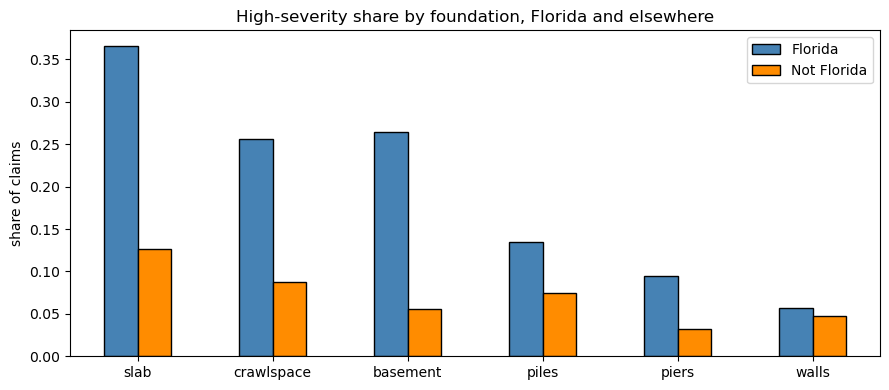

In [10]:
s3['building_group'] = np.where(
    s3['foundationType'] == '1', 'slab',
    np.where(s3['foundationType'].isin(list('456')), 'elevated (4-6)', 'basement or crawlspace'),
)
summary = s3.groupby(['place', 'building_group']).agg(
    claims=('building_group', 'size'),
    high_severity_share=('high_severity', 'mean'),
    median_payment_if_paid=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()),
    median_damage_over_coverage=('damage_ratio', 'median'),
)
print(summary.round(3))

mobile = s3['occupancyType'] == 14
print()
print(
    f"Mobile homes (occupancy 14): n = {mobile.sum():,}, "
    f"median coverage ${s3.loc[mobile, 'totalBuildingInsuranceCoverage'].median():,.0f}, "
    f"high-severity share {s3.loc[mobile, 'high_severity'].mean():.1%}"
)

plot_df = by_found['high_severity_share'].unstack('place').reindex(order)
fig, ax = plt.subplots(figsize=(9, 4))
plot_df.plot.bar(ax=ax, color=['steelblue', 'darkorange'], edgecolor='black')
ax.set_ylabel('share of claims')
ax.set_xlabel('')
ax.set_title('High-severity share by foundation, Florida and elsewhere')
ax.legend(title='')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**What the split shows.** On this sample:

| | Florida | Not Florida |
|---|---|---|
| Slab, high-severity share | 36.6% (8,768 claims) | 12.7% (3,446) |
| Elevated foundations (piles, piers, walls) | 9.5% (2,353) | 5.2% (1,818) |
| Slab ÷ elevated | about 3.9 times | about 2.4 times |
| Median damage / coverage, slab vs elevated | 0.35 vs 0.04 | 0.16 vs 0.04 |

Slab is higher in both places. The gap is larger in Florida than outside it. The single "four times" line in notebook 04 is the Florida-heavy slab clusters set against elevated clusters and against a basement cluster that is almost entirely outside Florida.

Basements are the clearest place mix-up. The basement cluster has a 6% high-severity share and is 4% Florida. In the split, non-Florida basements are 5.6% high severity (1,869 claims) and Florida basements are 26% (80 claims). Eighty claims is a thin cell, and it is enough to show that "basement homes are low severity" was a place pattern.

Mobile homes stay at 3.5% high severity with median coverage of $71,000. A building insured for $71,000 rarely reaches a damage cutoff of $106,127.

## 4.1 Clusters inside Florida only

The national groups were partly a Florida-versus-elsewhere split. This section drops every claim outside Florida and repeats the k sweep on the same features, using **all 147,246 Florida claims with a recorded foundation**, not a 20,000-claim sample. `high_severity` is still the national cutoff, building damage of at least $106,127. The silhouette is scored on 5,000 of the fitted claims, because scoring every pair of 147,246 rows is slow. The groups themselves are fit on every Florida row.


In [11]:
fl = w3[w3['state'] == 'FL'].copy()
X_fl = pd.get_dummies(fl[FL['RQ3']], columns=NOM3, dtype=int)
X_fl['totalBuildingInsuranceCoverage'] = np.log1p(X_fl['totalBuildingInsuranceCoverage'])
X_fl_s = StandardScaler().fit_transform(X_fl)
print(f'Florida claims with a foundation: {len(fl):,}    encoded columns: {X_fl.shape[1]}')

fl_rows = []
fitted = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_fl_s).labels_
    fitted[k] = labels
    counts = pd.Series(labels).value_counts()
    fl_rows.append({
        'k': k,
        'silhouette on 5,000': silhouette_score(X_fl_s, labels, sample_size=5000, random_state=SEED),
        'smallest group': int(counts.min()),
        'largest group': int(counts.max()),
        'largest share': counts.max() / len(labels),
    })
fl_sweep = pd.DataFrame(fl_rows)
print(fl_sweep.round(3).to_string(index=False))
best_k_fl = int(fl_sweep.loc[fl_sweep['k'] > 2, 'silhouette on 5,000'].idxmax())
best_k_fl = int(fl_sweep.loc[best_k_fl, 'k'])
print('Best k between 3 and 8:', best_k_fl)

def florida_profile(labels):
    frame = fl.copy()
    frame['cluster'] = labels
    profile = frame.groupby('cluster').agg(
        claims=('cluster', 'size'),
        high_severity_share=('high_severity', 'mean'),
        median_coverage=('totalBuildingInsuranceCoverage', 'median'),
    )
    profile['foundation'] = frame.groupby('cluster')['foundationType'].agg(
        lambda x: FOUNDATION.get(x.value_counts().index[0], x.value_counts().index[0]))
    profile['foundation share'] = frame.groupby('cluster')['foundationType'].agg(
        lambda x: x.value_counts(normalize=True).iloc[0])
    profile['flood zone'] = frame.groupby('cluster')['flood_zone_family'].agg(lambda x: x.value_counts().index[0])
    profile['zone share'] = frame.groupby('cluster')['flood_zone_family'].agg(
        lambda x: x.value_counts(normalize=True).iloc[0])
    profile['top occupancy'] = frame.groupby('cluster')['occupancyType'].agg(lambda x: x.value_counts().index[0])
    return profile.sort_values('high_severity_share', ascending=False)

print()
print('k = 2')
print(florida_profile(fitted[2]).round(3))
print()
print(f'k = {best_k_fl}')
print(florida_profile(fitted[best_k_fl]).round(3))

slab = fl[fl['foundationType'] == '1']
zone = slab.groupby('flood_zone_family').agg(
    claims=('flood_zone_family', 'size'),
    high_severity_share=('high_severity', 'mean'),
)
zone = zone[zone['claims'] >= 100].sort_values('high_severity_share', ascending=False)
print()
print('All Florida slab homes by flood zone (zones with at least 100 claims)')
print(zone.round(3))


Florida claims with a foundation: 147,246    encoded columns: 30


 k  silhouette on 5,000  smallest group  largest group  largest share
 2                0.445            4787         142459          0.967
 3                0.264            4786          98644          0.670
 4                0.278            4786          91317          0.620
 5                0.302            4786          89935          0.611
 6                0.327            3011         104803          0.712
 7                0.334            2824          89564          0.608
 8                0.312             114          84711          0.575
Best k between 3 and 8: 7

k = 2
         claims  high_severity_share  median_coverage foundation  foundation share flood zone  zone share  \
cluster                                                                                                     
0        142459                0.312         250000.0       slab             0.767         AE       0.845   
1          4787                0.031          73000.0      piles             0.5

**What all Florida claims show.** Using every Florida row does not produce tight groups. The best silhouette between k = 3 and k = 8 is **0.33 at k = 7**. The largest group holds **89,564 of 147,246** claims (61%). k = 2 scores **0.45**, higher than on the 20,000-claim sample, and it is mobile homes again: 4,787 claims, occupancy 14, median coverage $73,000, high-severity share 3%, against the other 142,459 claims.

The k = 7 groups:

| Group | Claims | High severity |
|---|---|---|
| Slab, zone AE, single family | 89,564 | 40% |
| Mixed foundations, zone AE, single family | 26,097 | 14% |
| Slab, zone X | 9,397 | 14% |
| Condo buildings, zone AE, median coverage $1,000,000 | 7,371 | 29% |
| Condo units, median coverage $0 | 7,208 | 2% |
| Mobile homes, median coverage $73,000 | 4,785 | 3% |
| Slab, zone A | 2,824 | 10% |

The $0-coverage units and the mobile homes are coverage patterns, not safer buildings. Two of the large groups are both mostly zone AE, so k-means did not find a clean gap there.

The flood zone among slab homes is stable once every Florida slab claim is counted:

| Flood zone | Slab claims | High severity |
|---|---|---|
| V | 2,912 | 52% |
| AO | 149 | 40% |
| AE | 92,013 | 39% |
| X | 9,113 | 14% |
| AH | 2,755 | 13% |
| A | 2,647 | 10% |

Zone V is still not its own cluster. K-means leaves those claims inside the large AE group. More rows make the zone rates steadier. They do not make the clusters distinct.


## 4.2 Other approaches and other feature combinations

The runs above use one feature list and k-means. This section changes the ingredients, on the same 20,000-claim national sample. Four combinations, plus a Gaussian mixture:

1. **Flood zone and foundation only.** Drop age, floors, occupancy, CRS, and coverage.
2. **The research question's list:** flood zone, foundation, the elevated flag, post-FIRM construction, floors, building age, latitude, and longitude. `elevationDifference` is missing on 66% of claims, so the elevated flag stands in for elevation.
3. **No category codes.** Elevated flag, post-FIRM, age, CRS class, latitude, longitude, and log coverage.
4. **Latitude and longitude only.**

For each combination the table is the silhouette for k = 2 through 8. A Gaussian mixture is fit to combination 3. Its BIC keeps falling as k grows if the data is not a few blobs. Lower BIC is a better fit.


In [12]:
from sklearn.mixture import GaussianMixture

def sweep(frame):
    Xs = StandardScaler().fit_transform(frame)
    rows = []
    for k in range(2, 9):
        labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs).labels_
        counts = pd.Series(labels).value_counts()
        rows.append({
            'k': k,
            'silhouette': silhouette_score(Xs, labels, sample_size=5000, random_state=SEED),
            'largest group': int(counts.max()),
        })
    return pd.DataFrame(rows), Xs

zone_found = pd.get_dummies(s3[['flood_zone_family', 'foundationType']], dtype=int)
question = pd.get_dummies(
    s3[['flood_zone_family', 'foundationType', 'numberOfFloorsInTheInsuredBuilding']], dtype=int)
question['elevated'] = s3['elevatedBuildingIndicator'].astype(int).to_numpy()
question['postFIRM'] = s3['postFIRMConstructionIndicator'].astype(int).to_numpy()
question['age'] = s3['building_age'].to_numpy()
question['lat'] = s3['latitude'].to_numpy()
question['lon'] = s3['longitude'].to_numpy()
numeric = pd.DataFrame({
    'elevated': s3['elevatedBuildingIndicator'].astype(int).to_numpy(),
    'postFIRM': s3['postFIRMConstructionIndicator'].astype(int).to_numpy(),
    'age': s3['building_age'].to_numpy(),
    'crs': s3['crsClassCode'].to_numpy(),
    'lat': s3['latitude'].to_numpy(),
    'lon': s3['longitude'].to_numpy(),
    'log_coverage': np.log1p(s3['totalBuildingInsuranceCoverage'].to_numpy()),
})
places = s3[['latitude', 'longitude']]

print('1. Zone and foundation only')
tab, _ = sweep(zone_found)
print(tab.round(3).to_string(index=False))
print('\n2. Zone, foundation, elevation, construction, latitude, longitude')
tab, _ = sweep(question)
print(tab.round(3).to_string(index=False))
print('\n3. No category codes')
tab, Xn = sweep(numeric)
print(tab.round(3).to_string(index=False))
print('\n4. Latitude and longitude only')
tab, Xp = sweep(places)
print(tab.round(3).to_string(index=False))

print('\nGaussian mixture on combination 3 (lower BIC is a better fit)')
for k in range(2, 8):
    mix = GaussianMixture(n_components=k, covariance_type='diag', random_state=SEED, n_init=2).fit(Xn)
    labels = mix.predict(Xn)
    sil = silhouette_score(Xn, labels, sample_size=5000, random_state=SEED)
    print(f'k = {k}   BIC {mix.bic(Xn):,.0f}   silhouette {sil:.3f}')

labels = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Xp).labels_
s3['geo'] = labels
geo = s3.groupby('geo').agg(
    claims=('geo', 'size'),
    high_severity_share=('high_severity', 'mean'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
    latitude=('latitude', 'median'),
    longitude=('longitude', 'median'),
)
print('\nLatitude/longitude, k = 4')
print(geo.round(3))


1. Zone and foundation only


 k  silhouette  largest group
 2       0.380          12214
 3       0.382          15972
 4       0.440          14725
 5       0.535          12621
 6       0.523          13860
 7       0.632          12149
 8       0.725           9861

2. Zone, foundation, elevation, construction, latitude, longitude


 k  silhouette  largest group
 2       0.261          12200
 3       0.292          12202
 4       0.295           9625
 5       0.299          10118
 6       0.352           9936
 7       0.389           9024
 8       0.387           9779

3. No category codes


 k  silhouette  largest group
 2       0.297          13470
 3       0.332           9557
 4       0.357           9286
 5       0.377           9260
 6       0.399           8557
 7       0.425           8510
 8       0.401           7715

4. Latitude and longitude only


 k  silhouette  largest group
 2       0.638          15545
 3       0.682          15173
 4       0.682          11699
 5       0.697          11576
 6       0.698          11571
 7       0.710          11532
 8       0.713          11528

Gaussian mixture on combination 3 (lower BIC is a better fit)


k = 2   BIC 109,939   silhouette 0.298


... (2 outputs left out)

k = 5   BIC -187,716   silhouette 0.292


k = 6   BIC -190,497   silhouette 0.295


k = 7   BIC -203,243   silhouette 0.259



Latitude/longitude, k = 4
     claims  high_severity_share  florida_share  latitude  longitude
geo                                                                 
0     11699                0.306          0.982      27.4      -82.2
1      3994                0.084          0.000      40.6      -75.5
2       603                0.114          0.000      38.0     -121.7
3      3704                0.089          0.074      30.2      -90.5


**What the other combinations show.**

| Combination | Best silhouette | What the groups are |
|---|---|---|
| Zone and foundation only | 0.73 at k = 8 | The common zone-and-foundation pairs. AE slab is 34% high severity; zone X slab is 13%; basement is 7%; elevated walls are 5%. |
| Zone, foundation, elevation, construction, and coordinates together | 0.39 at k = 7 | The same ingredients in one model. The largest group is still about half the sample. |
| No category codes | 0.43 at k = 7 | Mostly place and age: older Florida slab homes versus newer homes, the Northeast, and the West. |
| Latitude and longitude only | 0.71 at k = 8, and 0.68 already at k = 4 | Regions. At k = 4: Florida (31% high severity), the Northeast (8%), the Gulf outside Florida (9%), and the West (11%). |
| Gaussian mixture on the numeric columns | silhouette stays near 0.26–0.30 | BIC is still falling at k = 7, so the mixture does not prefer a small number of blobs. |

Two combinations clear the usual "separated" line of about 0.5, and both do it for a mechanical reason.

Zone and foundation are codes. Two claims with the same code land on the same point, so k-means is renaming the pairs that already exist. There are 42 zone-and-foundation pairs in the sample. The eight groups are the large pairs, and the severity gaps are the ones a plain table shows.

Latitude and longitude are rounded, so many claims share a point, and the points form regions. The severity gap in that map is Florida versus the other coasts. Notebook 04 left coordinates out of the clustering features because a coordinate records where the storms in this file occurred.

Putting the features together, which is what a risk profile would be, brings the silhouette back under 0.45. No combination tried here finds a set of distinct profiles beyond flood zone, foundation, and Florida.


## 5. What published studies found

These studies use NFIP claims. None of them reports seven stable building clusters.

- **Kousky and Michel-Kerjan (2017), Journal of Risk and Insurance.** More than 1 million claims from 1978–2012. Homes known to be elevated have claim amounts **16–18% lower** than other homes, after the other factors in their model. That is a smaller gap than a 3.9-times difference in the share of claims above $106,127. The two numbers answer different questions: theirs is an average dollar claim, and ours is the share of claims that cross a high cutoff. They also find that half of claims are under 10% of building value, so the typical claim is modest and a thin tail is severe. A public summary is [RFF Resources 191](https://www.resources.org/archives/a-look-at-35-years-of-flood-insurance-claims/). Paper: [doi:10.1111/jori.12106](https://doi.org/10.1111/jori.12106).
- **Wing, Pinter, Bates, and Kousky (2020), Nature Communications.** About 2 million claims. At a fixed water depth, damage as a share of building value is spread out and often bunched at both a small loss and a near-total loss. One depth does not produce one typical loss. A modest shift in damage can move many claims across a high dollar cutoff, which is one reason a 16–18% difference in average claim size can sit next to a much larger difference in a top-20% flag. Paper: [doi:10.1038/s41467-020-15264-2](https://doi.org/10.1038/s41467-020-15264-2).
- **Vishnu, Wojtkiewicz, and Ramanathan (FLOODrisk 2020).** Occupancy, the kind of flood (surge, riverine, or rainfall), flood zone, and code compliance are the main drivers of building and contents loss. Crawlspace losses are lower than slab losses at small depths. Basement claims look milder than the building damage because NFIP coverage for basements is limited. That limit is a reason to treat the low basement payments outside Florida with caution. Paper: [FLOODrisk 2020 pdf](https://repozitorium.omikk.bme.hu/server/api/core/bitstreams/f9008d57-ebd6-4b37-9d1c-beeaad6094f7/content).
- **Liu and Mostafavi, FloodGenome (2025).** This is the clustering paper closest to the question. It does not cluster claim rows on foundation codes. It aggregates claims to census block groups, clusters those places on mean damage ratio and the number of damaged buildings, and then predicts the level from elevation and the built environment. Place-level risk groups are a different question. This claims file cannot answer it: there is no count of policies in force, and the coordinates are rounded. Paper: [doi:10.1088/2634-4505/adb800](https://doi.org/10.1088/2634-4505/adb800).

Every row in our file is already a claim. A group of claimants with the same foundation is a split of vulnerability among buildings that flooded. It is not the probability that a building floods.

## 6. Answer to RQ3

Claims do not form tight groups with similar flood risk. On the same sample as notebook 04, K-means at k = 7 mostly renames the foundation code. The silhouette at that k is 0.25, and hierarchical clustering and PCA do not recover the same groups.

What does repeat, here and in the published claims studies, is coarser. **Slab-on-grade homes have higher claim severity than elevated homes.** In this sample the high-severity share is 37% for slab and 9% for elevated foundations in Florida (about 3.9 times), and 13% versus 5% outside Florida (about 2.4 times). Median damage as a share of coverage moves the same way, and both groups have median coverage of $250,000, so that gap is not the coverage cap.

The "about four times" sentence in notebook 04 is the Florida-heavy slab clusters compared with elevated clusters and with a basement cluster that is 4% Florida. Held inside one place, the slab-versus-elevated gap is about 3.9 times in Florida and about 2.4 times elsewhere. Kousky and Michel-Kerjan's controlled estimate is a 16–18% lower average claim for elevated homes. That is a different comparison (average dollars, with other factors held in the model), and Wing et al. show why a high dollar cutoff can move more than the average does: losses at a given depth are spread from small to near-total.

Two groups in the notebook 04 table should not be read as safer buildings. Non-Florida basements look mild, and Florida basements in this sample do not (26%, on 80 claims). Published work also finds that basement payments understate damage because coverage is limited. Mobile homes look mild on the high-severity flag because their median coverage is $71,000, below the $106,127 cutoff.

Payment and damage were not used to form the clusters. They were used only as this check.

Other choices of k do not produce a tighter set of risk profiles. The best silhouette is k = 2 (0.46 on the sample, 0.51 on all 250,406 claims with a foundation), and that split is mobile homes against every other claim, not two flood-risk levels. DBSCAN, using 16 nearest neighbors to set the neighborhood size, breaks the sample into about 110 small groups. Those groups are pure foundation and occupancy codes. KNN is not a clustering method, so it cannot answer this question.

PCA does not supply the missing groups. The first two components are 16% of the variance, and they mostly reload floors, occupancy, and foundation. K-means in that plane has a silhouette near 0.5, but the same labels scored on the original columns fall to about 0.13–0.19. Keeping 18 components (80% of the variance) leaves the k = 7 silhouette at 0.22 in the original space, and those groups do not match the groups from the original columns (ARI 0.29). The only split that stays separated after PCA is mobile homes against every other claim.


Inside Florida, using all 147,246 claims with a recorded foundation, the picture is the same kind of overlap. The best silhouette between k = 3 and k = 8 is **0.33 at k = 7**, and 89,564 claims sit in one slab, zone AE group. k = 2 (silhouette 0.45) is mobile homes against every other Florida claim. What the national clustering hid is the flood zone among Florida slab homes: zone V is 52% high severity (2,912 claims) and zone AE is 39% (92,013 claims), against 10–14% in zones A, AH, and X.


Other feature combinations do not produce a hidden set of profiles. Zone and foundation alone reach a silhouette of 0.73 at k = 8, because claims with the same code sit on the same point; those eight groups are the common zone-and-foundation pairs, and their severities are the ones in the Florida table. Latitude and longitude alone reach 0.68 at k = 4: Florida (31% high severity), the Northeast (8%), the Gulf outside Florida (9%), and the West (11%). Coordinates were left out of the original feature list because they record where the storms were. Putting zone, foundation, elevation, construction, and coordinates in one model drops the best silhouette to 0.39. A Gaussian mixture on the numeric columns does not settle on a small number of groups.
